# E1: Which segmentation model?

**Question.** Which model gives the best alpha for Modelia-like inputs (people with hair, fashion products), at what speed and memory?

**Data** (`data/e1_subset.md`): 45 images with ground truth in 3 groups + 10 real fashion photos without ground truth.

| Group | n | Ground truth | Judged by |
|---|---:|---|---|
| A_people (PPM-100) | 15 | soft alpha matte | IoU, Boundary IoU, MAE |
| B_products (DIS-VD Accessories) | 20 | binary mask | IoU, Boundary IoU, MAE |
| C_structure (DIS-VD, hand-picked) | 10 | binary mask | same, reported apart (stress set) |
| D_real (fashion photos) | 10 | none | visual only: every result is saved |

**Models**: BiRefNet, BiRefNet_lite, BiRefNet-matting, BEN2, InSPyReNet, IS-Net, U²-Net (all run here), RMBG-2.0 (public Space, reference only: non-commercial licence).

**Hypotheses (written before the run)**
1. BiRefNet (general) has the best IoU / Boundary IoU on B and C (it is trained on DIS5K-TR).
2. On A (hair), the matting-style models (BiRefNet-matting, BEN2) have the lowest MAE, but BiRefNet-matting's number is optimistic: PPM-100 is in its training set.
3. BiRefNet_lite is clearly faster than BiRefNet for a small accuracy loss.
4. U²-Net (320 px input) is clearly the worst on Boundary IoU.
5. Every model struggles on D09 (white top on white background) and on the bottom of the black dress in D10 (low light).

**How the notebook works.** Section 3 runs each model once and saves its alpha as a PNG, with time and memory per image. Everything after it (metrics, tables, figures) only reads those PNGs. A model that is already done on this device is skipped, so the notebook can be re-run after an interruption.

**This run (the saved outputs).** One run on Google Colab (Tesla T4, torch 2.11 + CUDA 13) through the VS Code Colab extension, with images and results on Google Drive; `python experiments/fetch_e1_results.py` then copies the results into `results/e1/`. The notebook also runs locally on CPU (`data/e1/`, `results/e1/`), but no full CPU run was made: the only CPU times are the single-image demos (`EXPERIMENTS.md`, E1.0). Two code edits were made after the run, so they did not produce the saved outputs (notes in sections 4 and 5). Result and decision: section 8.

## 1. Setup

In [1]:
import importlib.util
import sys
from pathlib import Path

# Colab runtimes ship the google.colab package (also with the VS Code extension, where it may not be imported yet).
IN_COLAB = importlib.util.find_spec("google.colab") is not None
REPO_URL = "https://github.com/MedSahbiBenKalia/modelia-bg-change"

if IN_COLAB:
    ROOT = Path("/content/modelia-bg-change")
    if ROOT.exists():
        !git -C {ROOT} pull -q
    else:
        !git clone -q {REPO_URL} {ROOT}
    # Lower bounds only in requirements.txt, so Colab keeps its CUDA torch.
    # rembg[gpu] brings onnxruntime-gpu; BEN2 is not on PyPI.
    # pip may upgrade a package this Python has already imported (numpy, ...): the old copy stays in
    # memory and later imports mix two versions (seen: "cannot import name '_slice'"). Detect it.
    from importlib import invalidate_caches
    from importlib.metadata import version
    WATCH = {"numpy": "numpy", "scipy": "scipy", "pillow": "PIL", "pandas": "pandas"}  # pip name: import name
    before = {pkg: version(pkg) for pkg, mod in WATCH.items() if mod in sys.modules}
    !pip install -q -r {ROOT}/requirements.txt "rembg[gpu]" transparent-background gradio_client git+https://github.com/PramaLLC/BEN2.git
    invalidate_caches()
    changed = [f"{pkg} {v} -> {version(pkg)}" for pkg, v in before.items() if version(pkg) != v]
    if changed:
        raise RuntimeError(f"pip upgraded {', '.join(changed)} after it was imported: "
                           "Runtime > Restart session, then run all again (the second run installs nothing).")
else:
    # Repo root = first parent folder that holds requirements.txt (works from experiments/ or the root).
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))
print("repo:", ROOT, "| colab:", IN_COLAB)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
repo: /content/modelia-bg-change | colab: True


In [2]:
import gc
import os
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn.functional as F
from PIL import Image

from bgchange.composite import over_colour
from bgchange.io import load_alpha, load_rgb, parse_hex, save_alpha
from bgchange.metrics import boundary_iou, iou, mae


def cpu_name():
    # Readable CPU model for the speed table (platform.processor() is not, on Windows).
    try:
        if sys.platform == "win32":
            import winreg
            key = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
        return next(l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name"))
    except Exception:
        return platform.processor() or "unknown CPU"


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32  # fp16 is slow / unsupported on CPU
HARDWARE = torch.cuda.get_device_name() if DEVICE == "cuda" else f"{cpu_name()} ({os.cpu_count()} threads)"
print("device:", DEVICE, DTYPE, "|", HARDWARE, "| torch", torch.__version__)
if IN_COLAB and DEVICE == "cpu":
    print("WARNING: this Colab server has no GPU. Pick a GPU server (e.g. T4) when connecting.")

device: cuda torch.float16 | Tesla T4 | torch 2.11.0+cu130


### Data and results folders

On Colab the images come from Google Drive (`MyDrive/modelia-e1`, uploaded from `data/e1/`) and results are written next to them in `modelia-e1/results/`, so they survive a disconnect. If mounting Drive fails, the shared folder is downloaded with `gdown` instead, and results stay on the Colab disk only.

Locally: `data/e1/` and `results/e1/`.

In [3]:
DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1kBxHVZqNXHGMIEhsNyoxQw_4XF3tB1xk?usp=sharing"


def find_e1_root(base: Path) -> Path:
    # The folder that holds A_people/, B_products/, ... (the upload may have added one level).
    for cand in [base, *base.glob("*"), *base.glob("*/*")]:
        if (cand / "A_people").is_dir():
            return cand
    raise FileNotFoundError(f"no A_people/ folder under {base}")


if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        mydrive = Path("/content/drive/MyDrive")
        base = next(p for p in [mydrive / "modelia-e1", *mydrive.glob("*/modelia-e1"), *mydrive.glob("*/*/modelia-e1")] if p.is_dir())
        RESULTS = base / "results"
    except Exception as e:  # mount not available, or folder not found
        print("Drive not used:", repr(e), "-> downloading the shared folder with gdown")
        import gdown
        base = Path("/content/modelia-e1")
        if not (base.exists() and any(base.iterdir())):
            gdown.download_folder(DRIVE_FOLDER_URL, output=str(base), quiet=True)
        RESULTS = Path("/content/e1_results")
        print("WARNING: results are only on the Colab disk:", RESULTS)
    E1_ROOT = find_e1_root(base)
else:
    E1_ROOT = ROOT / "data" / "e1"
    RESULTS = ROOT / "results" / "e1"

ALPHAS = RESULTS / "alphas"      # alphas/<model>/<image name>.png
FIGURES = RESULTS / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
print("images :", E1_ROOT)
print("results:", RESULTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
images : /content/drive/MyDrive/modelia-e1/e1
results: /content/drive/MyDrive/modelia-e1/results


## 2. The subset

In [5]:
subset = pd.read_csv(ROOT / "data" / "e1_subset.csv", keep_default_na=False)


def local(rel: str) -> Path:
    # CSV paths are 'e1/<group>/...' relative to data/.
    return E1_ROOT / Path(rel).relative_to("e1")


missing = [r for r in subset["image"] if not local(r).exists()]
missing += [g for g in subset["gt"] if g and not local(g).exists()]
assert not missing, f"{len(missing)} files missing (upload not finished?), e.g. {missing[:3]}"

labelled = subset[subset["gt_type"] != "none"]
print(subset.groupby(["group", "gt_type"]).size().to_string())

group        gt_type
A_people     alpha      15
B_products   binary     20
C_structure  binary     10
D_real       none       10


## 3. Models

Every model is wrapped the same way: `load()` returns `predict(img) -> alpha`, a float array in [0, 1] **at the input's full size**, plus a short description of the backend. Pre- and post-processing (resize, normalisation, upsampling back) are inside `predict`, because the pipeline pays for them too.

| Model | Code | Input size | Licence |
|---|---|---|---|
| BiRefNet / _lite / -matting | `transformers`, `trust_remote_code` | 1024×1024 | MIT |
| BEN2 (base) | `ben2` | 1024×1024 | MIT |
| InSPyReNet | `transparent-background` (mode `base`) | 1024×1024 | MIT |
| IS-Net (general use) | `rembg` (ONNX) | 1024×1024 | Apache-2.0 |
| U²-Net | `rembg` (ONNX) | 320×320 | Apache-2.0 |

In [6]:
from torchvision import transforms
from transformers import AutoModelForImageSegmentation

to_tensor_1024 = transforms.Compose([
    transforms.Resize((1024, 1024)),  # BiRefNet's training resolution
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet stats
])


def load_birefnet(repo_id):
    torch.set_float32_matmul_precision("high")
    model = AutoModelForImageSegmentation.from_pretrained(repo_id, trust_remote_code=True)
    model = model.to(DEVICE, DTYPE).eval()  # cast explicitly: the hub weights are stored in fp16

    def predict(img):
        x = to_tensor_1024(img).unsqueeze(0).to(DEVICE, DTYPE)
        with torch.no_grad():
            logits = model(x)[-1]  # list of side outputs, the last one is the final prediction
            alpha = F.interpolate(logits.sigmoid(), size=img.size[::-1], mode="bilinear", align_corners=False)
        return alpha[0, 0].float().cpu().numpy()

    return predict, f"torch {DEVICE} {str(DTYPE).replace('torch.', '')}"


def load_ben2():
    from ben2 import BEN_Base
    model = BEN_Base.from_pretrained("PramaLLC/BEN2").to(DEVICE).eval()

    def predict(img):
        fg = model.inference(img.copy(), refine_foreground=False)  # copy: BEN2 calls putalpha() on its input
        return np.asarray(fg.getchannel("A"), np.float32) / 255

    return predict, f"torch {DEVICE}" + (" (fp16 autocast)" if DEVICE == "cuda" else " float32")


def load_inspyrenet():
    from transparent_background import Remover
    remover = Remover(mode="base", device="cuda:0" if DEVICE == "cuda" else "cpu")

    def predict(img):
        sal = remover.process(img, type="map")  # saliency map, no threshold -> soft
        return np.asarray(sal.convert("L"), np.float32) / 255

    return predict, f"torch {DEVICE}"


def load_rembg(model_name):
    import onnxruntime as ort
    from rembg import new_session, remove
    if DEVICE == "cuda" and hasattr(ort, "preload_dlls"):
        try:
            ort.preload_dlls()  # use the CUDA / cuDNN libraries that come with torch
        except Exception as e:
            print("onnxruntime preload_dlls failed:", repr(e))
    providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if DEVICE == "cuda" else ["CPUExecutionProvider"]
    session = new_session(model_name, providers=providers)
    # A CUDA failure only shows on the first run (seen on Colab: cuDNN HEURISTIC_QUERY_FAILED), and ONNX Runtime
    # then moves the session to CPU for good. So run one blank image (rembg resizes it to the model size) first,
    # then read what ONNX Runtime really uses. This run counts in load_s.
    remove(Image.new("RGB", (64, 64)), session=session, only_mask=True)
    used = session.inner_session.get_providers()[0]
    if DEVICE == "cuda" and used != "CUDAExecutionProvider":
        print(f"WARNING: {model_name} runs on CPU (ONNX Runtime could not load CUDA): its timing_cuda rows are CPU times.")

    def predict(img):
        mask = remove(img, session=session, only_mask=True)  # uint8 PIL image, soft (no post-processing)
        return np.asarray(mask, np.float32) / 255

    return predict, f"onnxruntime {used}"


MODELS = {
    "BiRefNet": lambda: load_birefnet("ZhengPeng7/BiRefNet"),
    "BiRefNet_lite": lambda: load_birefnet("ZhengPeng7/BiRefNet_lite"),
    "BiRefNet-matting": lambda: load_birefnet("ZhengPeng7/BiRefNet-matting"),
    "BEN2": load_ben2,
    "InSPyReNet": load_inspyrenet,
    "IS-Net": lambda: load_rembg("isnet-general-use"),
    "U2-Net": lambda: load_rembg("u2net"),
}
INPUT_SIZE = {"U2-Net": 320}  # all others: 1024

### Run every model on all 55 images

One model at a time: load, one warm-up image (not timed: first-call overheads, CUDA kernel selection), then every image is timed from PIL image in to full-size alpha out (image decoding excluded). The alpha is saved to `alphas/<model>/<name>.png`, the times to `timing_<device>/<model>.csv`.

**Memory** = memory in use after each image minus memory in use just before loading the model (so weights + what the run keeps), max over the images:
- GPU: memory used on the whole device (`torch.cuda.mem_get_info`), so ONNX Runtime models are measured like torch ones; torch's allocator keeps its peak reserved, so this is close to the true peak.
- CPU: RAM of this process (RSS). Sampled between images, so it is a lower bound of the true peak, and approximate (Python does not always give freed memory back to the OS).

A model already done on this device is skipped; delete its `timing_<device>/<model>.csv` to re-run it. A model that fails (download, install, out of memory) is reported in `FAILED` and the others still run.

In [7]:
TIMING = RESULTS / f"timing_{DEVICE}"


def mem_in_use_mb():
    # GPU: memory used on the whole device (sees torch and ONNX Runtime); CPU: this process's RAM (RSS).
    if DEVICE == "cuda":
        free, total = torch.cuda.mem_get_info()
        return (total - free) / 2**20
    return psutil.Process().memory_info().rss / 2**20


def run_model(name):
    out_dir, timing_csv = ALPHAS / name, TIMING / f"{name}.csv"
    if timing_csv.exists() and all((out_dir / f"{n}.png").exists() for n in subset["name"]):
        print(f"{name}: already done on {DEVICE}, skipped")
        return
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    mem0 = mem_in_use_mb()
    t0 = time.perf_counter()
    predict, backend = MODELS[name]()
    load_s = time.perf_counter() - t0
    predict(load_rgb(local(subset["image"].iloc[0])))  # warm-up, not timed

    rows = []
    for r in subset.to_dict("records"):
        img = load_rgb(local(r["image"]))
        t = time.perf_counter()
        alpha = predict(img)
        rows.append({"model": name, "name": r["name"], "group": r["group"], "width": img.width, "height": img.height,
                     "seconds": time.perf_counter() - t, "mem_increase_mb": mem_in_use_mb() - mem0})
        save_alpha(alpha, out_dir / f"{r['name']}.png")

    TIMING.mkdir(parents=True, exist_ok=True)
    df = pd.DataFrame(rows).assign(device=DEVICE, hardware=HARDWARE, backend=backend, load_seconds=load_s)
    df.to_csv(timing_csv, index=False)
    print(f"{name}: {backend} | median {df.seconds.median():.2f} s/img | memory +{df.mem_increase_mb.max():.0f} MB")
    del predict
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


FAILED = {}
for name in MODELS:
    try:
        run_model(name)
    except NameError:  # a notebook-order error (an earlier cell not run), not a model failure: stop
        raise
    except Exception as e:  # download, install or out-of-memory error: report it, run the other models
        FAILED[name] = repr(e)[:300]
        print(f"{name}: FAILED {FAILED[name]}")
    gc.collect()  # after the except block: the traceback no longer holds the failed model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
print("failed:", FAILED or "none")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/754 [00:00<?, ?it/s]

BiRefNet: torch cuda float16 | median 0.40 s/img | memory +2496 MB


Loading weights:   0%|          | 0/586 [00:00<?, ?it/s]

BiRefNet_lite: torch cuda float16 | median 0.20 s/img | memory +1674 MB


...

BiRefNet-matting: torch cuda float16 | median 0.40 s/img | memory +2438 MB


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


BEN2: torch cuda (fp16 autocast) | median 0.61 s/img | memory +3212 MB


/usr/local/lib/python3.13/dist-packages/transparent_background/gui.py:24: UserWarning: Failed to import flet. Ignore this message when you do not need GUI mode.
  warnings.warn('Failed to import flet. Ignore this message when you do not need GUI mode.')


Settings -> Mode=base, Device=cuda:0, Torchscript=disabled
InSPyReNet: torch cuda | median 1.03 s/img | memory +3694 MB
EP Error: [ONNXRuntimeError] : 11 : EP_FAIL : Non-zero status code returned while running Conv node. Name:'/stage2/rebnconvin/conv_s1/Conv' Status Message: Failed to initialize CUDNN Frontend: /onnxruntime_src/onnxruntime/core/providers/cuda/cudnn_fe_call.cc:117 std::conditional_t<THRW, void, onnxruntime::common::Status> onnxruntime::CudaCall(ERRTYPE, const char*, const char*, SUCCTYPE, const char*, const char*, int) [with ERRTYPE = cudnn_frontend::error_object; bool THRW = true; SUCCTYPE = cudnn_frontend::error_code_t; std::conditional_t<THRW, void, common::Status> = void] /onnxruntime_src/onnxruntime/core/providers/cuda/cudnn_fe_call.cc:109 std::conditional_t<THRW, void, onnxruntime::common::Status> onnxruntime::CudaCall(ERRTYPE, const char*, const char*, SUCCTYPE, const char*, const char*, int) [with ERRTYPE = cudnn_frontend::error_object; bool THRW = true; SUCCTYP

### RMBG-2.0 (reference only)

Non-commercial licence, so not a candidate for the pipeline; called through the public Hugging Face Space (no token). The free ZeroGPU quota is small, so by default only group D is sent. Times include upload and queueing, so they are not comparable and not reported. Errors (quota) are printed and skipped; images already done are not sent again.

In [8]:
import tempfile

from gradio_client import Client, handle_file

RMBG_GROUPS = ["D_real"]  # add "A_people", "B_products", ... if the quota allows


def rmbg_alpha(client, img):
    with tempfile.TemporaryDirectory() as tmp:
        f = Path(tmp) / "in.jpg"
        img.save(f, quality=95)
        _, png_path = client.predict(image=handle_file(str(f)), api_name="/image")  # (slider, transparent PNG)
        alpha = Image.open(png_path).convert("RGBA").getchannel("A").resize(img.size, Image.BILINEAR)
    return np.asarray(alpha, np.float32) / 255


todo = [r for r in subset[subset["group"].isin(RMBG_GROUPS)].to_dict("records")
        if not (ALPHAS / "RMBG-2.0_API" / f"{r['name']}.png").exists()]
if todo:
    try:
        client = Client("briaai/BRIA-RMBG-2.0", httpx_kwargs={"timeout": 120})
    except Exception as e:  # Space asleep, renamed or its API changed: reference row only, skip it
        print("RMBG-2.0 Space not reachable:", repr(e)[:200])
        todo = []
    for r in todo:
        try:
            save_alpha(rmbg_alpha(client, load_rgb(local(r["image"]))), ALPHAS / "RMBG-2.0_API" / f"{r['name']}.png")
            print("ok", r["name"])
        except Exception as e:
            print("failed", r["name"], repr(e)[:200])

Loaded as API: https://briaai-bria-rmbg-2-0.hf.space
ok D01_vintage_shoot
ok D02_white_sneaker
ok D03_shirt_rack
failed D04_lace_dress AppError('You have exceeded your ZeroGPU runs limit. Authenticate with a Hugging Face token for more quota - https://huggingface.co/settings/tokens')
failed D05_jump_white_studio AppError('You have exceeded your ZeroGPU runs limit. Authenticate with a Hugging Face token for more quota - https://huggingface.co/settings/tokens')
failed D06_logo_tshirt AppError('You have exceeded your ZeroGPU runs limit. Authenticate with a Hugging Face token for more quota - https://huggingface.co/settings/tokens')
failed D07_hanger_shirt AppError('You have exceeded your ZeroGPU runs limit. Authenticate with a Hugging Face token for more quota - https://huggingface.co/settings/tokens')
failed D08_runway_sheer_veil AppError('You have exceeded your ZeroGPU runs limit. Authenticate with a Hugging Face token for more quota - https://huggingface.co/settings/tokens')
failed D09

## 4. Speed and memory

Median seconds per image (the mean is pulled up by the few 5000+ px images). `load_s` = loading the weights (they are downloaded once, before). One row per model and device (this run: Tesla T4 only).

**Read with care.**
- IS-Net and U2-Net ran on Colab's CPU, not on the GPU. ONNX Runtime's CUDA backend failed on the first image they ran (cuDNN `HEURISTIC_QUERY_FAILED`) and fell back to CPU. Their saved backend says `CUDAExecutionProvider` because it was read before that image; their GPU memory (+4 MB, +0 MB) shows what really happened. After the run, `load_rembg` was changed to run one blank image before reading the backend, so a re-run labels them correctly.
- The BiRefNet models ran in fp16 and InSPyReNet in fp32, so their speeds are not a like-for-like comparison.

In [9]:
def md_table(df: pd.DataFrame, floatfmt="{:.3f}") -> str:
    # Markdown table without the tabulate dependency.
    cols = [df.index.name or ""] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        cells = [floatfmt.format(v) if isinstance(v, float) else str(v) for v in row]
        lines.append("| " + " | ".join([str(idx), *cells]) + " |")
    return "\n".join(lines)


timing_files = sorted(RESULTS.glob("timing_*/*.csv"))
if timing_files:
    timing = pd.concat(map(pd.read_csv, timing_files))
    speed = timing.groupby(["device", "model"]).agg(
        hardware=("hardware", "first"), backend=("backend", "first"),
        median_s=("seconds", "median"), mean_s=("seconds", "mean"), max_s=("seconds", "max"),
        load_s=("load_seconds", "first"), mem_mb=("mem_increase_mb", "max")).reset_index()
    speed.insert(2, "input_px", speed["model"].map(lambda m: INPUT_SIZE.get(m, 1024)))
    speed = speed.sort_values(["device", "model"], key=lambda s: s.map(lambda v: list(MODELS).index(v) if v in MODELS else v))
    speed = speed.set_index("model")
    speed.to_csv(RESULTS / "e1_speed.csv")
    (RESULTS / "e1_speed.md").write_text(md_table(speed, "{:.2f}"), encoding="utf-8")
    display(speed.round(2))
else:
    print("no timing files yet")

,device,input_px,hardware,backend,median_s,mean_s,max_s,load_s,mem_mb
model,,,,,,,,,
BiRefNet,cuda,1024,Tesla T4,torch cuda float16,0.40,0.42,0.53,11.98,2496.0
BiRefNet_lite,cuda,1024,Tesla T4,torch cuda float16,0.20,0.21,0.35,0.57,1674.0
BiRefNet-matting,cuda,1024,Tesla T4,torch cuda float16,0.40,0.42,0.56,0.97,2438.0
BEN2,cuda,1024,Tesla T4,torch cuda (fp16 autocast),0.61,0.66,1.12,1.15,3212.0
InSPyReNet,cuda,1024,Tesla T4,torch cuda,1.03,1.08,1.56,3.32,3694.0
IS-Net,cuda,1024,Tesla T4,onnxruntime CUDAExecutionProvider,3.54,3.60,4.40,1.65,4.0
U2-Net,cuda,320,Tesla T4,onnxruntime CUDAExecutionProvider,1.40,1.44,1.86,0.21,0.0


## 5. Accuracy on the labelled groups (A, B, C)

Per image and model: **IoU** (alpha and ground truth thresholded at 0.5), **Boundary IoU** (IoU on a band of 2 % of the image diagonal inside each outline; Cheng et al., CVPR 2021) and **MAE** on the soft alpha. The ground truth is compared at its full resolution.

Training-data overlap (checked on the model cards, see `data/e1_subset.md`) is marked with `*` in the summary.

IS-Net's B and C scores were added to the overlap list after the run (same status as BEN2: trained on DIS5K, splits not stated), so the saved tables below do not show their `*`.

In [10]:
rows = []
model_dirs = sorted(d for d in ALPHAS.iterdir() if d.is_dir()) if ALPHAS.exists() else []
for r in labelled.to_dict("records"):
    gt = load_alpha(local(r["gt"]))
    for d in model_dirs:
        p = d / f"{r['name']}.png"
        if p.exists():
            pred = load_alpha(p)
            rows.append({"model": d.name, "group": r["group"], "name": r["name"],
                         "iou": iou(pred, gt), "biou": boundary_iou(pred, gt), "mae": mae(pred, gt)})
metrics = pd.DataFrame(rows)
if len(metrics):
    # A run interrupted mid-model leaves alphas for part of a group only: that mean would not be comparable.
    n_group = metrics.group.map(labelled.groupby("group").size())
    n_done = metrics.groupby(["model", "group"]).name.transform("size")
    for (m, g), d in metrics[n_done < n_group].groupby(["model", "group"]):
        print(f"{m} on {g}: only {len(d)}/{n_group[d.index[0]]} images, left out")
    metrics = metrics[n_done == n_group]
metrics.to_csv(RESULTS / "e1_metrics.csv", index=False)
print(len(metrics), "rows ->", RESULTS / "e1_metrics.csv")

315 rows -> /content/drive/MyDrive/modelia-e1/results/e1_metrics.csv


In [11]:
LEAKS = {  # (model, group): reason; see data/e1_subset.md
    ("BiRefNet-matting", "A_people"): "PPM-100 is in its training set",
    ("BiRefNet", "B_products"): "DIS-VD is its validation set", ("BiRefNet", "C_structure"): "DIS-VD is its validation set",
    ("BiRefNet_lite", "B_products"): "DIS-VD is its validation set", ("BiRefNet_lite", "C_structure"): "DIS-VD is its validation set",
    ("BEN2", "B_products"): "trained on DIS5K, splits not stated", ("BEN2", "C_structure"): "trained on DIS5K, splits not stated",
    ("IS-Net", "B_products"): "trained on DIS5K, splits not stated", ("IS-Net", "C_structure"): "trained on DIS5K, splits not stated",
    ("RMBG-2.0_API", "B_products"): "may be trained on DIS-VD (claim by the BEN2 authors)",
    ("RMBG-2.0_API", "C_structure"): "may be trained on DIS-VD (claim by the BEN2 authors)",
}
ORDER = [m for m in [*MODELS, "RMBG-2.0_API"] if m in set(metrics.get("model", []))]

if len(metrics):
    # Mean per model and group, plus "A+B" = the fashion-relevant images pooled (35 images).
    per_group = metrics.groupby(["model", "group"])[["iou", "biou", "mae"]].mean()
    ab_rows = metrics[metrics.group.isin(["A_people", "B_products"])]
    n_ab = labelled.group.isin(["A_people", "B_products"]).sum()
    ab_rows = ab_rows.groupby("model").filter(lambda d: len(d) == n_ab)  # else A+B would silently be A only
    ab = ab_rows.groupby("model")[["iou", "biou", "mae"]].mean()
    ab["group"] = "A+B"
    summary = pd.concat([per_group.reset_index(), ab.reset_index()])
    summary.to_csv(RESULTS / "e1_summary.csv", index=False)

    lines = []
    for metric, better in [("iou", "higher"), ("biou", "higher"), ("mae", "lower")]:
        t = summary.pivot(index="model", columns="group", values=metric).loc[ORDER]
        t = t[[g for g in ["A_people", "B_products", "C_structure", "A+B"] if g in t.columns]]
        shown = t.map(lambda v: f"{v:.3f}").astype(object)
        for (m, g) in LEAKS:
            if m in shown.index and g in shown.columns:
                shown.loc[m, g] += " *"
        lines += [f"### {metric.upper()} ({better} is better)", "", md_table(shown), ""]
        print(metric.upper(), f"({better} is better)")
        display(shown)
    lines += ["`*` training-data overlap:", ""] + [f"- {m} on {g}: {why}" for (m, g), why in LEAKS.items()]
    (RESULTS / "e1_summary.md").write_text("\n".join(lines), encoding="utf-8")

IOU (higher is better)


group,A_people,B_products,C_structure,A+B
model,,,,
BiRefNet,0.987,0.939 *,0.895 *,0.959
BiRefNet_lite,0.986,0.836 *,0.866 *,0.900
BiRefNet-matting,0.987 *,0.671,0.580,0.807
BEN2,0.923,0.913 *,0.847 *,0.917
InSPyReNet,0.984,0.952,0.946,0.965
IS-Net,0.928,0.947,0.941,0.939
U2-Net,0.902,0.310,0.401,0.563


BIOU (higher is better)


group,A_people,B_products,C_structure,A+B
model,,,,
BiRefNet,0.946,0.901 *,0.854 *,0.920
BiRefNet_lite,0.936,0.790 *,0.811 *,0.852
BiRefNet-matting,0.952 *,0.620,0.541,0.762
BEN2,0.863,0.863 *,0.792 *,0.863
InSPyReNet,0.932,0.926,0.929,0.929
IS-Net,0.830,0.917,0.919,0.880
U2-Net,0.805,0.267,0.245,0.498


MAE (lower is better)


group,A_people,B_products,C_structure,A+B
model,,,,
BiRefNet,0.003,0.012 *,0.026 *,0.008
BiRefNet_lite,0.004,0.051 *,0.033 *,0.031
BiRefNet-matting,0.003 *,0.107,0.146,0.063
BEN2,0.025,0.021 *,0.055 *,0.023
InSPyReNet,0.005,0.011,0.017,0.008
IS-Net,0.020,0.013,0.019,0.016
U2-Net,0.019,0.224,0.242,0.136


## 6. Labelled hard cases (picked by rule, not by eye)

For each group: the image with the **lowest mean IoU** over the 7 local models, and the image where the models **disagree most** (highest std of IoU). Each row: input, ground truth, then each model's alpha. A second figure zooms on the window where the mean error is largest (useful for hair).

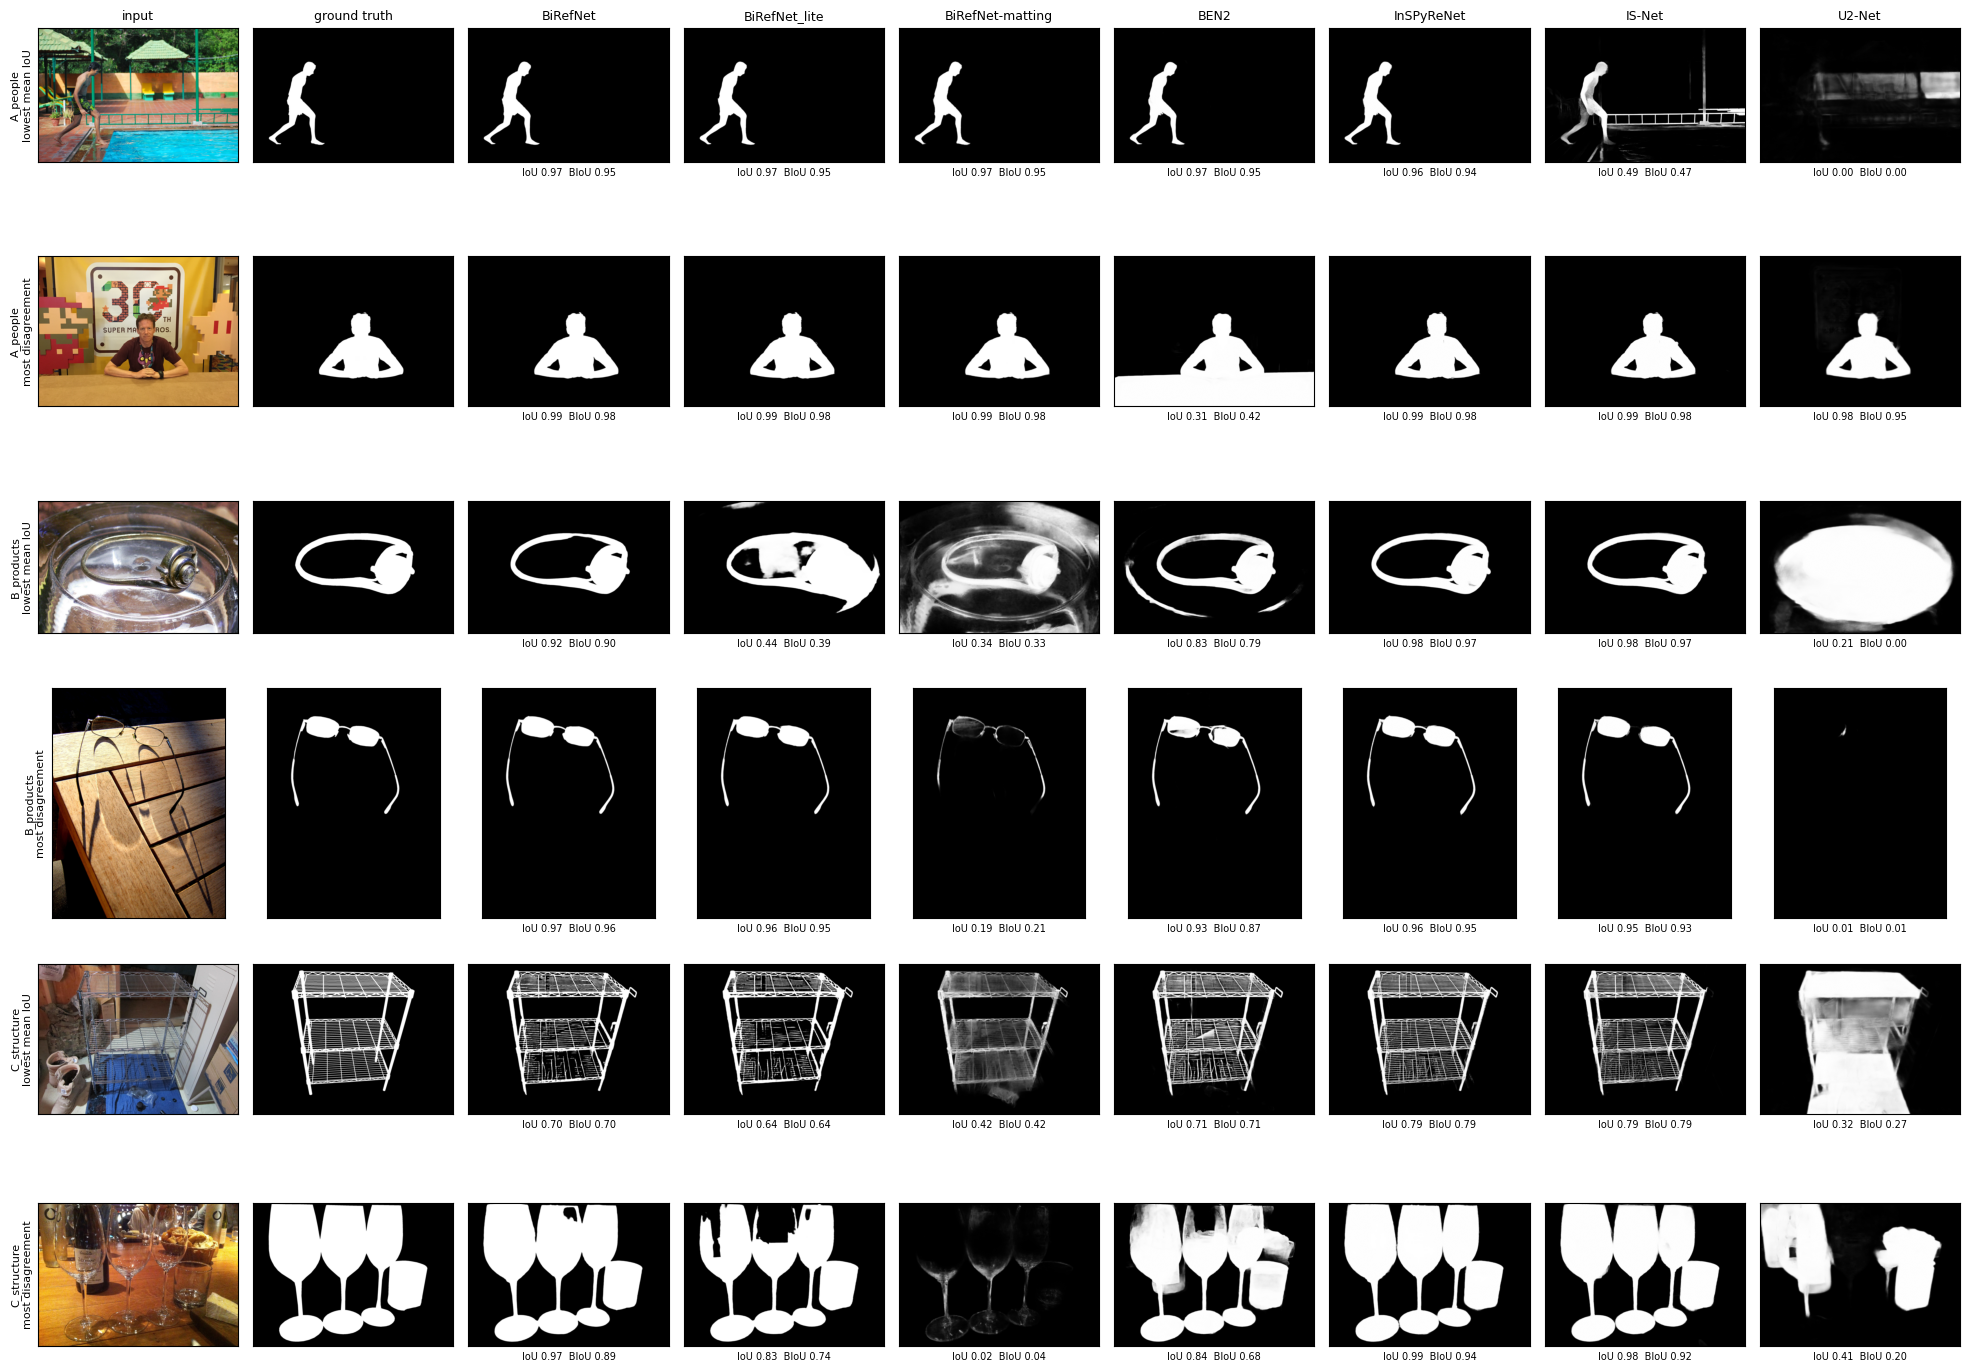

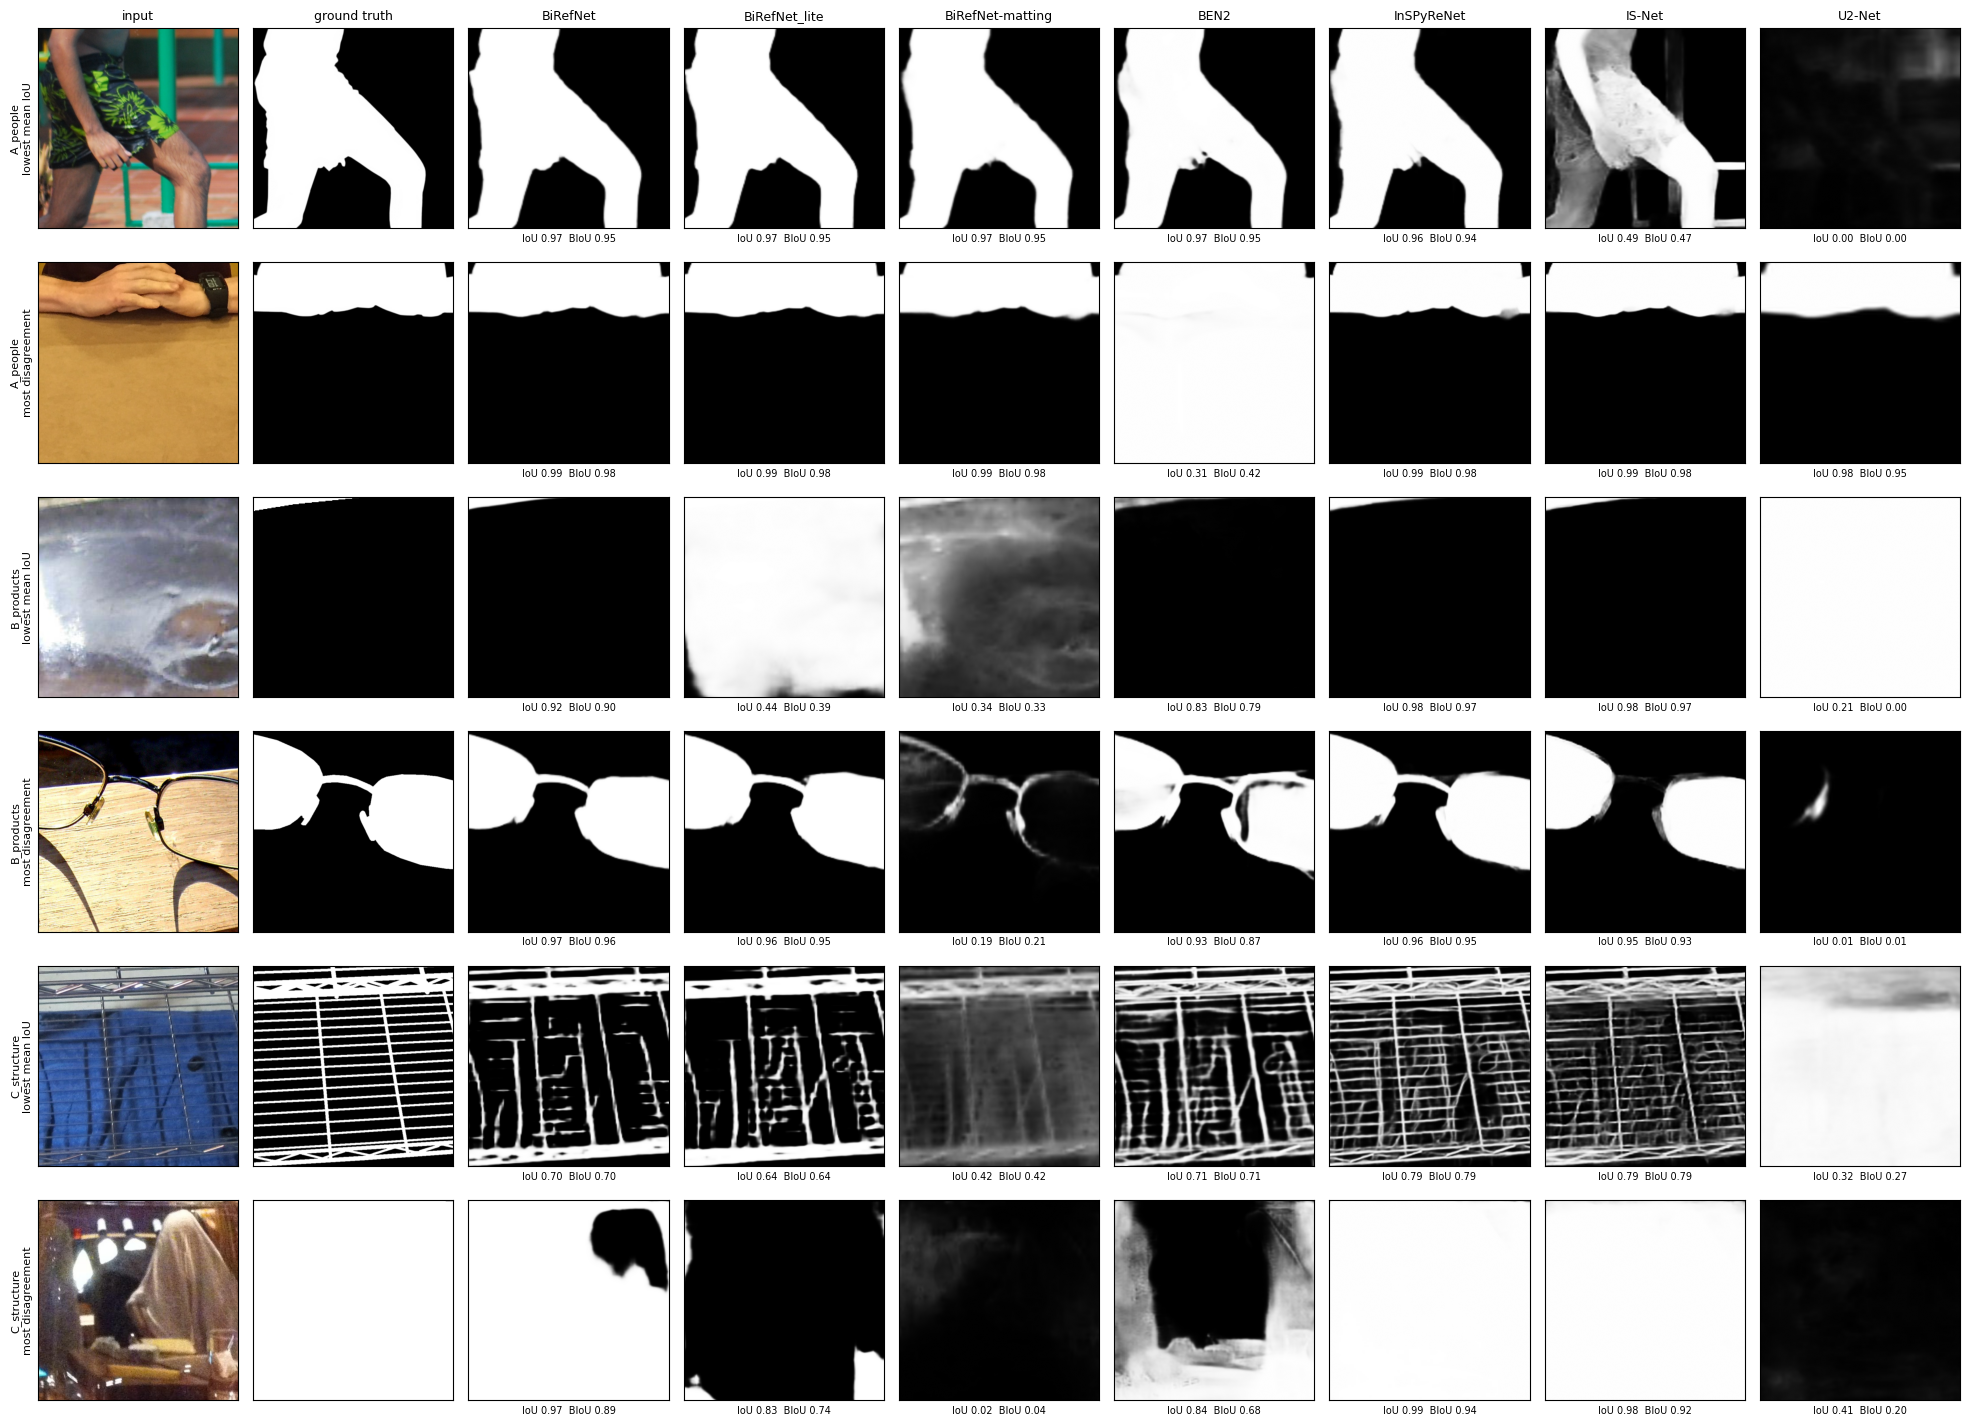

In [12]:
import cv2

# Models with an alpha for every labelled image: each figure row needs all of them.
SHOW = [m for m in MODELS if len(metrics) and (metrics.model == m).sum() == len(labelled)]


def thumb(a, size=512):
    im = a if isinstance(a, Image.Image) else Image.fromarray((np.clip(a, 0, 1) * 255).astype(np.uint8))
    im = im.copy()
    im.thumbnail((size, size))
    return im


def pick_hard_cases(metrics):
    local_m = metrics[metrics.model.isin(SHOW)]
    stats = local_m.groupby(["group", "name"]).iou.agg(["mean", "std"]).fillna(0).reset_index()  # std is NaN with one model
    picks = []
    for g, s in stats.groupby("group"):
        hardest = s.loc[s["mean"].idxmin(), "name"]
        rest = s[s["name"] != hardest]
        picks += [(g, hardest, "lowest mean IoU"), (g, rest.loc[rest["std"].idxmax(), "name"], "most disagreement")]
    return picks


def worst_window(name, frac=0.25):
    # Top-left corner + size of the square window where the mean |alpha - gt| over the models is largest.
    r = labelled.set_index("name").loc[name]
    gt = load_alpha(local(r["gt"]))
    err = np.mean([np.abs(load_alpha(ALPHAS / m / f"{name}.png") - gt) for m in SHOW], axis=0)
    k = max(8, int(frac * min(gt.shape)))
    smooth = cv2.blur(err, (k, k))  # mean error of the k x k window centred on each pixel
    cy, cx = np.unravel_index(smooth.argmax(), smooth.shape)
    y0, x0 = np.clip(cy - k // 2, 0, gt.shape[0] - k), np.clip(cx - k // 2, 0, gt.shape[1] - k)
    return y0, x0, k


def grid(picks, zoom=False, path=None):
    cols = ["input", "ground truth", *SHOW]
    fig, axes = plt.subplots(len(picks), len(cols), figsize=(2.2 * len(cols), 2.4 * len(picks)), squeeze=False)
    for i, (g, name, why) in enumerate(picks):
        r = labelled.set_index("name").loc[name]
        panels = [load_rgb(local(r["image"])), load_alpha(local(r["gt"]))]
        panels += [load_alpha(ALPHAS / m / f"{name}.png") for m in SHOW]
        if zoom:
            y0, x0, k = worst_window(name)
            panels = [np.asarray(p)[y0:y0 + k, x0:x0 + k] for p in panels]
            panels[0] = Image.fromarray(panels[0])
        for j, (ax, p) in enumerate(zip(axes[i], panels)):
            ax.imshow(thumb(p), cmap=None if j == 0 else "gray", vmin=0, vmax=255)
            ax.set_xticks([]), ax.set_yticks([])
            if i == 0:
                ax.set_title(cols[j], fontsize=9)
            if j >= 2:
                m = metrics[(metrics.model == SHOW[j - 2]) & (metrics.name == name)].iloc[0]
                ax.set_xlabel(f"IoU {m.iou:.2f}  BIoU {m.biou:.2f}", fontsize=7)
        axes[i][0].set_ylabel(f"{g}\n{why}", fontsize=8)
    plt.tight_layout()
    if path:
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=110)
    plt.show()


if SHOW:
    picks = pick_hard_cases(metrics)
    pd.DataFrame(picks, columns=["group", "name", "why"]).to_csv(RESULTS / "e1_hard_cases.csv", index=False)
    grid(picks, path=FIGURES / "e1_labelled_hard_cases.png")
    grid(picks, zoom=True, path=FIGURES / "e1_labelled_hard_cases_zoom.png")

## 7. Real fashion photos (group D): every result

No ground truth, so these are judged by eye. Each model's alpha is composited on `BG_HEX` (a saturated colour makes halos and missing hair easy to see). One figure per photo in `figures/D/`; every composite is also saved to `composites/<model>/<name>.jpg`.

D09 and D10 have no known licence: their figures are saved to disk (kept out of git) but not shown in the notebook, so the committed notebook does not contain them.

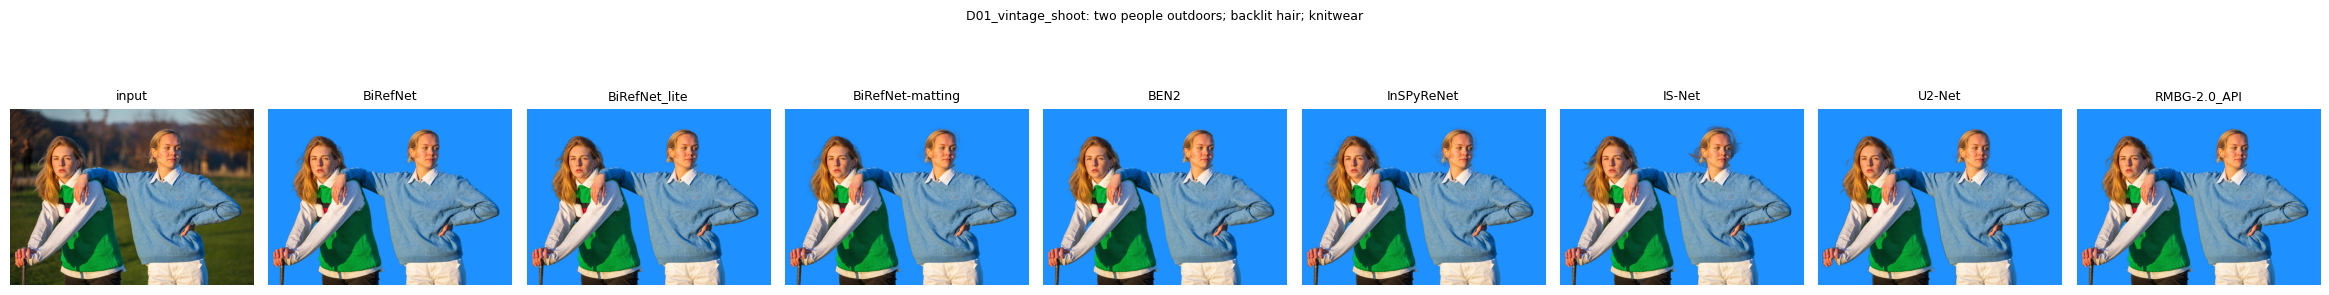

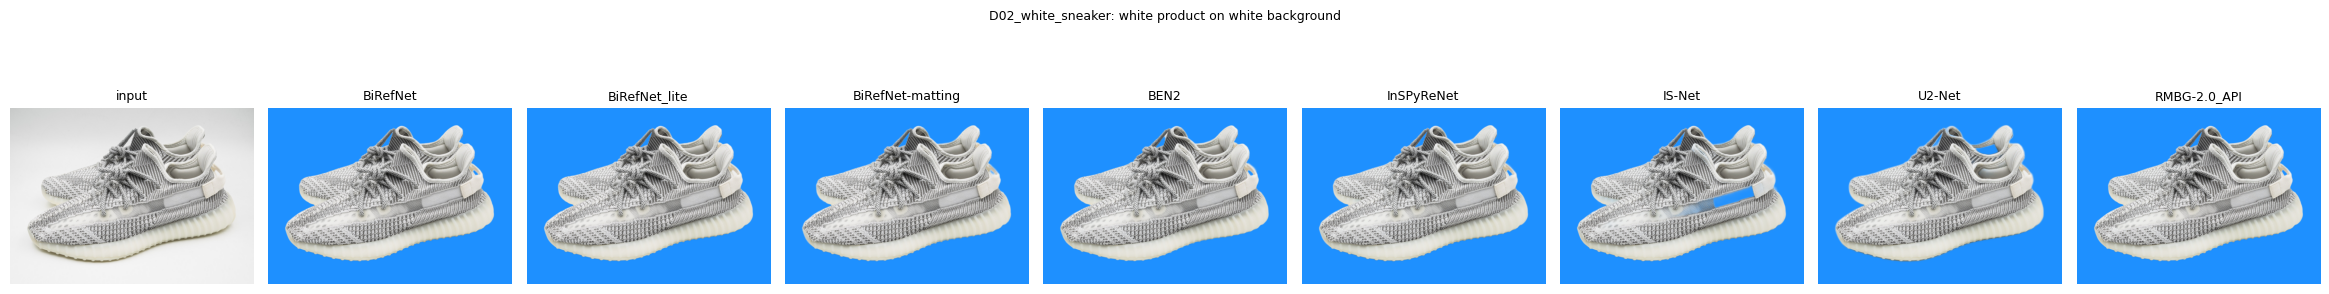

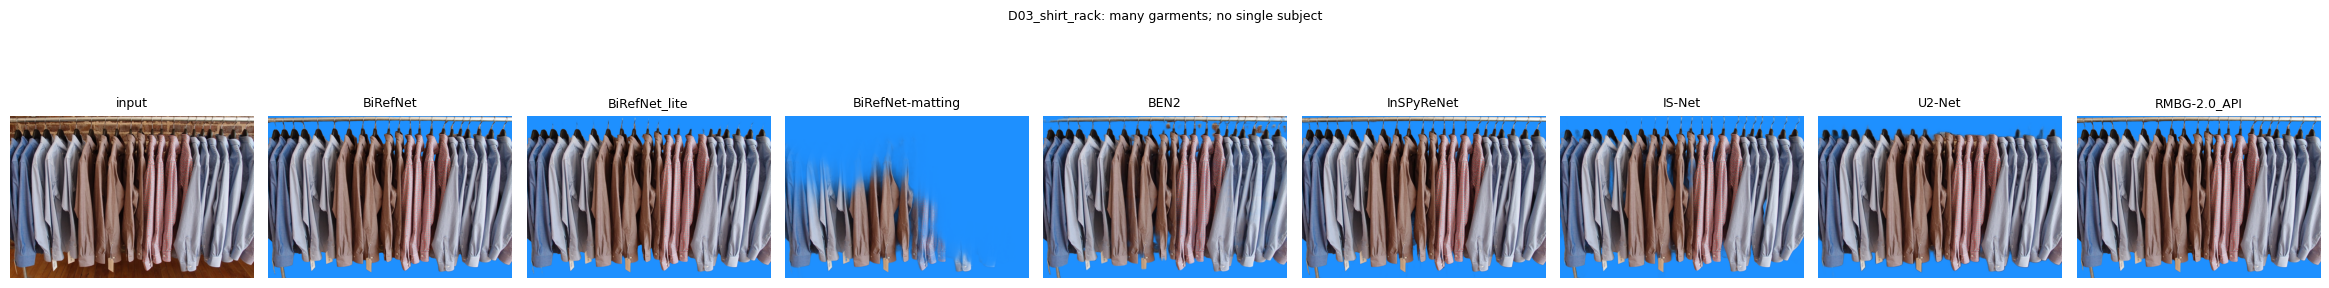

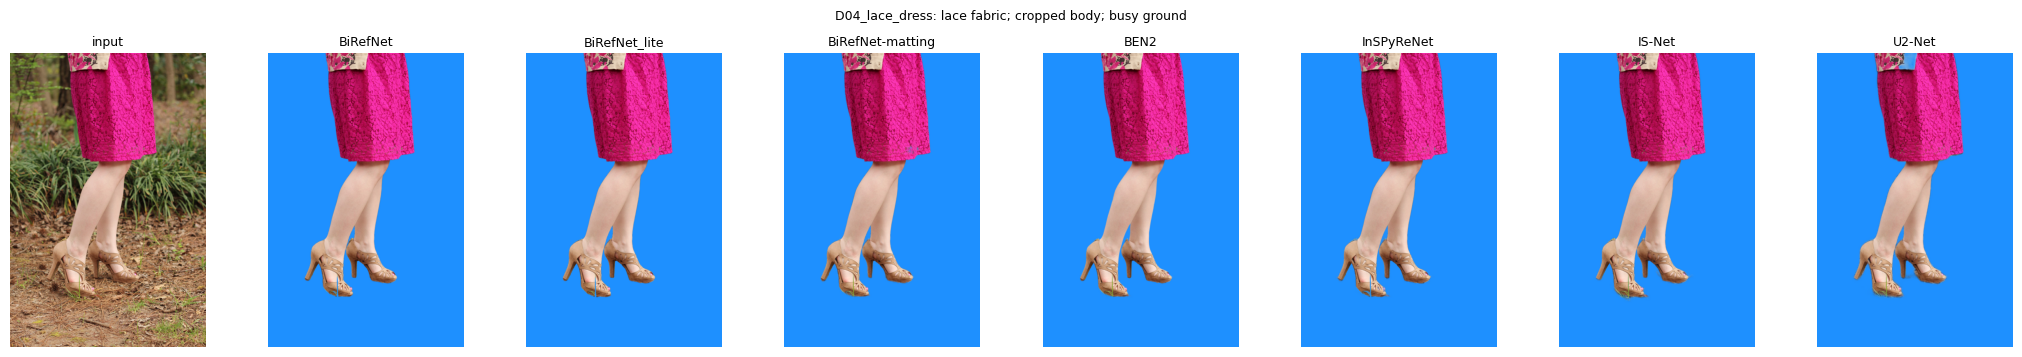

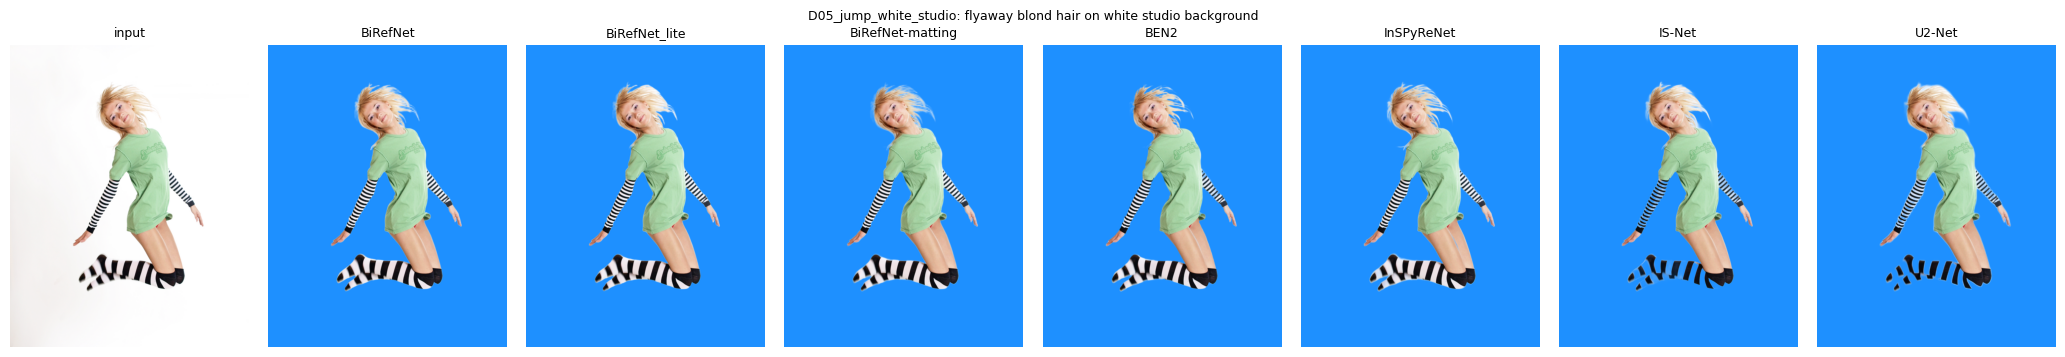

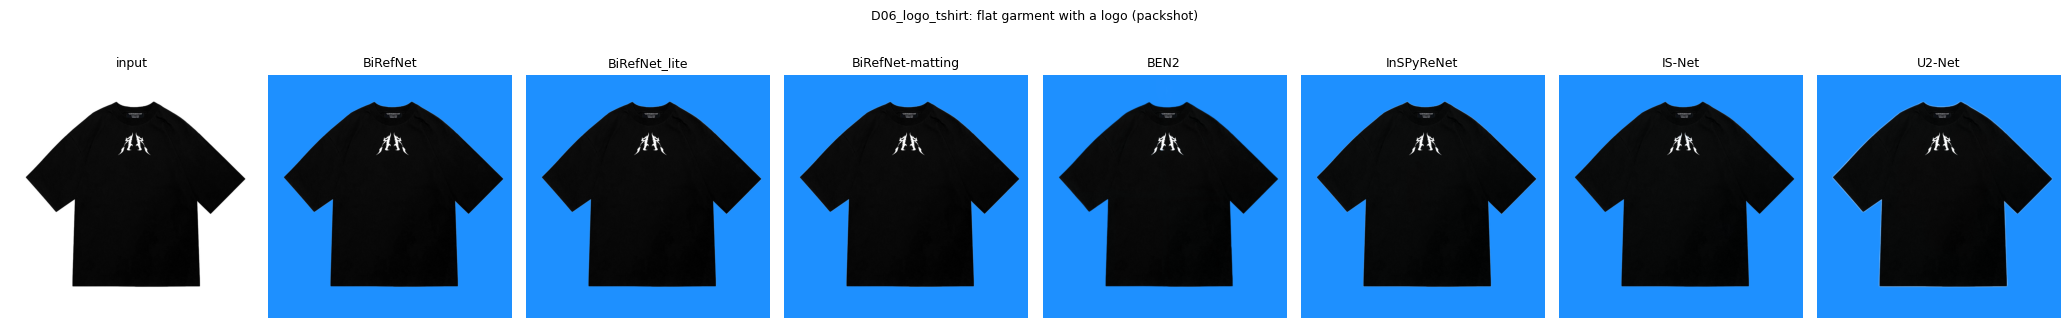

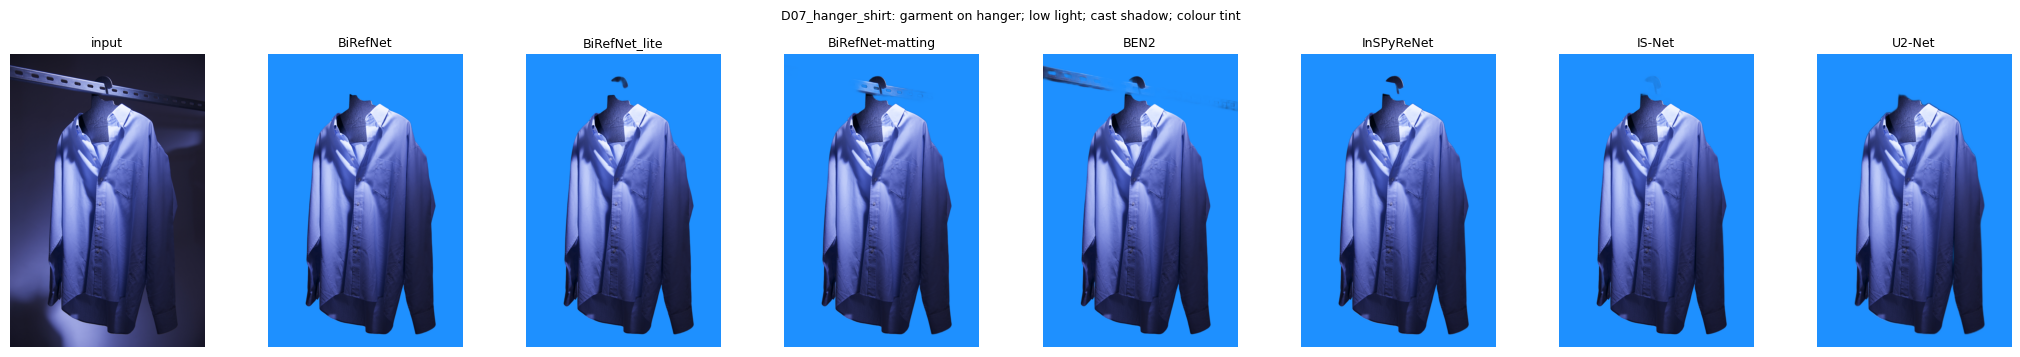

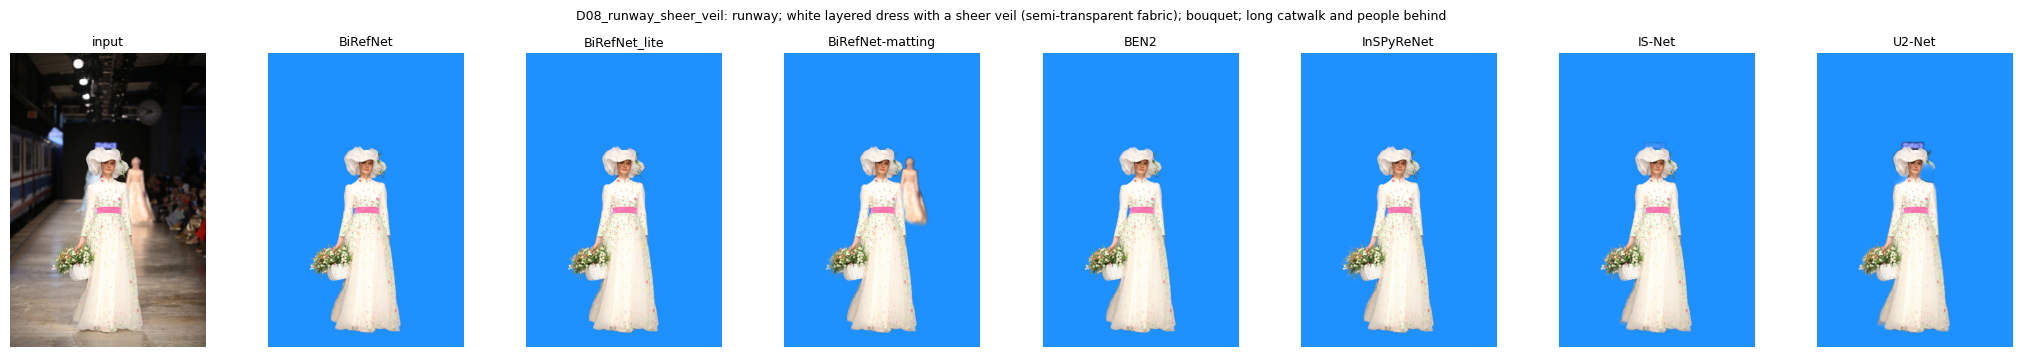

D09_white_on_white: no known licence, figure saved to /content/drive/MyDrive/modelia-e1/results/figures/D only
D10_low_light: no known licence, figure saved to /content/drive/MyDrive/modelia-e1/results/figures/D only


In [13]:
BG_HEX = "#1E90FF"
bg_rgb = parse_hex(BG_HEX)
D_MODELS = [m for m in [*MODELS, "RMBG-2.0_API"] if (ALPHAS / m).is_dir()]

for r in subset[subset["group"] == "D_real"].to_dict("records"):
    img = load_rgb(local(r["image"]))
    panels, titles = [img], ["input"]
    for m in D_MODELS:
        p = ALPHAS / m / f"{r['name']}.png"
        if not p.exists():
            continue
        comp = over_colour(img, load_alpha(p), bg_rgb)
        out = RESULTS / "composites" / m / f"{r['name']}.jpg"
        out.parent.mkdir(parents=True, exist_ok=True)
        thumb(comp, 1600).save(out, quality=92)
        panels.append(comp), titles.append(m)
    if len(panels) == 1:
        continue
    fig, axes = plt.subplots(1, len(panels), figsize=(2.6 * len(panels), 3.6))
    for ax, p, t in zip(axes, panels, titles):
        ax.imshow(thumb(p, 800)), ax.set_title(t, fontsize=9), ax.axis("off")
    fig.suptitle(f"{r['name']}: {r['note']}", fontsize=9)
    plt.tight_layout()
    (FIGURES / "D").mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / "D" / f"{r['name']}.png", dpi=110)
    if "unknown" in r["source"]:
        print(f"{r['name']}: no known licence, figure saved to {FIGURES / 'D'} only")
        plt.close(fig)
    else:
        plt.show()

## 8. Result and decision

Full entry: `EXPERIMENTS.md`, E1.1 (paired test: `experiments/e1_paired.py`, output in `results/e1/e1_paired.md`).

- **Chosen: BiRefNet (general).** On people + products (A+B) it ties InSPyReNet (IoU -0.006, Wilcoxon p = 0.61). It is better on people (lower MAE on 15/15 images); InSPyReNet is better on accessories (B) and thin structures (C).
- On the real photos, InSPyReNet lets the background show through the bottom of the black dress (D10); BiRefNet drops the hanger hook (D07) but keeps the garment whole.
- Ruled out: BiRefNet_lite (fails on 3 products, IoU 0.15 to 0.57), BiRefNet-matting (fails on objects that are not people), BEN2 (takes the desk as part of one portrait, keeps the clothes rail in D07), IS-Net and U2-Net (old baselines with large failures).
- Hypotheses: H1 rejected, H2 and H3 partly true, H4 confirmed, H5 rejected for D09 and partly true for D10 (details in E1.1).